# Task 1 — CNN from Scratch for Cat vs. Dog Classification, with Class-Imbalance Handling
**Pathline Training Academy — Machine Learning Internship**

## 1. Objective
1. Load and preprocess a cat/dog image dataset.
2. **Detect** class imbalance in the training data.
3. Build and train a **Convolutional Neural Network (CNN) from scratch** (no pre-trained weights) and evaluate it.
4. **Resolve** the imbalance (class weighting), retrain the same CNN, and re-evaluate.
5. **Compare** both models to measure the impact of handling imbalance.

**Dataset:** a 4,000-image subset of the Kaggle *Dogs vs. Cats* dataset
(3,000 training images + 1,000 test images, equal numbers of cats and dogs).

## 2. Setup & Data Download
`download_data.py` downloads only the subset used here (~100 MB) into `data/`, so the notebook is fully reproducible.

In [1]:
import os, glob, random, time, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # hide TensorFlow start-up info messages
warnings.filterwarnings("ignore", category=UserWarning)
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)   # makes Python, NumPy and TensorFlow results reproducible

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
DATA_DIR = "data"
CLASS_NAMES = ["cat", "dog"]       # label 0 = cat, label 1 = dog
os.makedirs("images", exist_ok=True)

if not os.path.isdir(DATA_DIR):
    import subprocess, sys
    subprocess.run([sys.executable, "download_data.py"], check=True)

print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 3. Data Quality Check
Image datasets scraped from the web often contain corrupted or unreadable files that crash training halfway through.
Every image is opened once with Pillow and any broken file is excluded.

In [2]:
from PIL import Image

def list_images(split, cls):
    return sorted(glob.glob(os.path.join(DATA_DIR, split, cls, "*.jpg")))

def is_valid(path):
    try:
        with Image.open(path) as im:
            im.verify()
        return True
    except Exception:
        return False

all_files = {(s, c): list_images(s, c) for s in ["train", "test"] for c in ["cats", "dogs"]}
for key, files in all_files.items():
    valid = [f for f in files if is_valid(f)]
    print(f"{key[0]:>5}/{key[1]:<4}: {len(files)} files, {len(files) - len(valid)} corrupted")
    all_files[key] = valid

train/cats: 1500 files, 0 corrupted


train/dogs: 1500 files, 0 corrupted
 test/cats: 500 files, 0 corrupted


 test/dogs: 500 files, 0 corrupted


## 4. Building the Train / Validation / Test Splits — with an Imbalanced Training Set
The original dataset is perfectly balanced, so to study the imbalance problem the **training set is made imbalanced on purpose,
with a 4 : 1 ratio** (1,200 cats vs. 300 dogs). This mimics a common real-world situation: one class is much easier to collect
than the other.

The **validation and test sets stay balanced**, because they represent the real world, where we want to recognise
cats and dogs equally well.

| Split | Cats | Dogs | Purpose |
|---|---|---|---|
| Train | 1,200 | 300 | learn the weights (imbalanced on purpose) |
| Validation | 300 | 300 | early stopping / monitoring |
| Test | 500 | 500 | final, untouched evaluation |

In [3]:
rng = random.Random(SEED)
cats = all_files[("train", "cats")][:]; rng.shuffle(cats)
dogs = all_files[("train", "dogs")][:]; rng.shuffle(dogs)

train_files = cats[:1200] + dogs[:300]
train_labels = [0] * 1200 + [1] * 300
val_files = cats[1200:1500] + dogs[300:600]
val_labels = [0] * 300 + [1] * 300
test_files = all_files[("test", "cats")] + all_files[("test", "dogs")]
test_labels = [0] * len(all_files[("test", "cats")]) + [1] * len(all_files[("test", "dogs")])

print(f"Train: {len(train_files)}  |  Validation: {len(val_files)}  |  Test: {len(test_files)}")

Train: 1500  |  Validation: 600  |  Test: 1000


## 5. Detecting the Class Imbalance

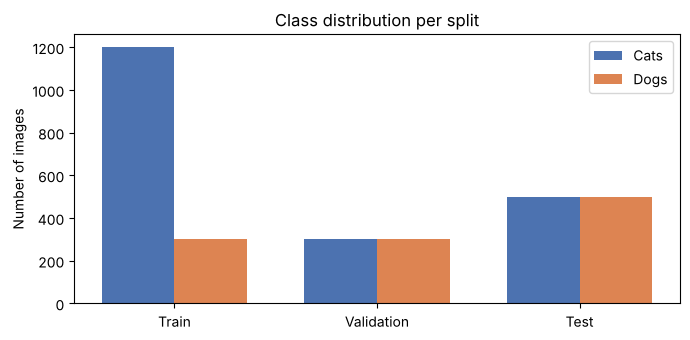

Training imbalance ratio (cats : dogs) = 4.0 : 1
A model that always predicts 'cat' would already be 80% accurate on the TRAINING data
...but only 50% accurate on the balanced test set.


In [4]:
counts = {name: [np.sum(np.array(lbls) == i) for i in range(2)]
          for name, lbls in [("Train", train_labels), ("Validation", val_labels), ("Test", test_labels)]}

fig, ax = plt.subplots(figsize=(7, 3.5))
x = np.arange(3)
ax.bar(x - 0.18, [c[0] for c in counts.values()], 0.36, label="Cats", color="#4C72B0")
ax.bar(x + 0.18, [c[1] for c in counts.values()], 0.36, label="Dogs", color="#DD8452")
ax.set_xticks(x, counts.keys()); ax.set_ylabel("Number of images"); ax.legend()
ax.set_title("Class distribution per split")
plt.tight_layout(); plt.savefig("images/class_distribution.png", dpi=120); plt.show()

n_cat, n_dog = counts["Train"]
print(f"Training imbalance ratio (cats : dogs) = {n_cat / n_dog:.1f} : 1")
print(f"A model that always predicts 'cat' would already be {n_cat / (n_cat + n_dog):.0%} accurate on the TRAINING data")
print("...but only 50% accurate on the balanced test set.")

**Why this is a problem:** with 4× more cats, the loss function is dominated by cat images. The network can lower its loss
simply by leaning toward "cat", so it tends to **under-detect dogs** (low dog recall). Plain accuracy on imbalanced data hides this,
so per-class recall and balanced accuracy are tracked as well.

## 6. Preprocessing Pipeline (`tf.data`)
For each image: read the file → decode the JPEG → **resize to 128×128** → keep pixel values as floats.
Pixel values are **normalised from [0, 255] to [0, 1]** inside the model with a `Rescaling` layer, so the exact same
preprocessing is applied automatically at prediction time.

`cache()` keeps decoded images in memory after the first epoch, and `prefetch()` prepares the next batch while the current one trains.

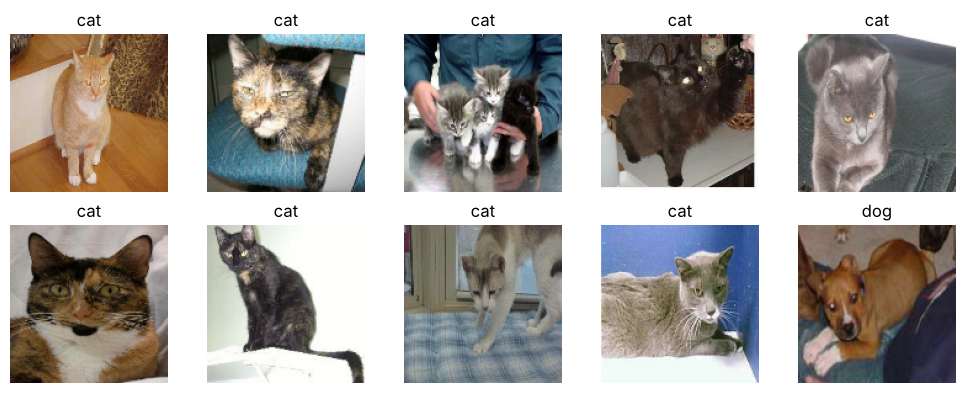

In [5]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    return img, label

def make_dataset(files, labels, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((files, labels))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).cache()
    if shuffle:
        ds = ds.shuffle(len(files), seed=SEED)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_files, train_labels, shuffle=True)
val_ds = make_dataset(val_files, val_labels)
test_ds = make_dataset(test_files, test_labels)

# Show a few training images
plt.figure(figsize=(10, 4))
for images, labels in train_ds.take(1):
    for i in range(10):
        ax = plt.subplot(2, 5, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(CLASS_NAMES[int(labels[i])]); plt.axis("off")
plt.tight_layout(); plt.savefig("images/sample_images.png", dpi=100); plt.show()

## 7. CNN Architecture (built from scratch)

```
Input 128×128×3
→ Data augmentation (random flip, rotation, zoom)     — training only
→ Rescaling 1/255                                     — normalise pixels to [0, 1]
→ [Conv 3×3, 32 filters  → BatchNorm → ReLU → MaxPool 2×2]   → 64×64×32
→ [Conv 3×3, 64 filters  → BatchNorm → ReLU → MaxPool 2×2]   → 32×32×64
→ [Conv 3×3, 128 filters → BatchNorm → ReLU → MaxPool 2×2]   → 16×16×128
→ [Conv 3×3, 128 filters → BatchNorm → ReLU → MaxPool 2×2]   → 8×8×128
→ Global Average Pooling → Dropout(0.3) → Dense(128, ReLU) → Dropout(0.3)
→ Dense(1, Sigmoid)                                   — probability that the image is a dog
```

* **Convolution layers** learn filters that detect local patterns — edges first, then textures (fur), then parts (ears, snouts).
* **Batch normalisation** re-centres and re-scales each layer's outputs during training, which makes training faster and more stable.
* **Max pooling** halves the spatial size, keeping the strongest responses and making the model tolerant to small shifts.
* **Filters increase (32 → 128)** as the image shrinks, so deeper layers can represent more complex features.
* **Global Average Pooling** turns each feature map into one number, which needs far fewer parameters than `Flatten` and reduces overfitting.
* **Dropout** randomly switches off neurons during training — another regulariser for a small dataset.
* **Sigmoid + binary cross-entropy** is the standard output/loss pair for a two-class problem.
* **Data augmentation** creates slightly altered copies of the training images every epoch, so the network sees more variety.

Both experiments use **exactly the same architecture and settings**, so any difference in results comes only from how the imbalance is handled.

In [6]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="augmentation")

def build_cnn():
    inputs = keras.Input(shape=IMG_SIZE + (3,))
    x = data_augmentation(inputs)
    x = layers.Rescaling(1.0 / 255)(x)
    for filters in [32, 64, 128, 128]:
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return model

build_cnn().summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 258,529 (1009.88 KB)

 Trainable params: 257,825 (1007.13 KB)

 Non-trainable params: 704 (2.75 KB)

## 8. Training & Evaluation Helpers
* **EarlyStopping** stops training when validation loss has not improved for 10 epochs and restores the best weights — this prevents overfitting. It only starts watching after epoch 15: with batch normalisation the validation loss jumps around in the first epochs, and stopping that early would compare two half-trained models.
* **ReduceLROnPlateau** halves the learning rate when validation loss stalls for 4 epochs, so the optimiser can take finer steps.
* **Metrics:** accuracy, **balanced accuracy** (average of cat recall and dog recall), per-class precision/recall/F1, and the confusion matrix.

In [7]:
from sklearn.metrics import classification_report, confusion_matrix, balanced_accuracy_score, accuracy_score, f1_score

EPOCHS = 60

def train(model, class_weight=None):
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, start_from_epoch=15, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5),
    ]
    start = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                        class_weight=class_weight, callbacks=callbacks, verbose=2)
    print(f"Training time: {(time.time() - start) / 60:.1f} min, epochs run: {len(history.history['loss'])}")
    return history

def evaluate(model, name):
    probs = model.predict(test_ds, verbose=0).ravel()
    preds = (probs >= 0.5).astype(int)
    y_true = np.array(test_labels)
    cm = confusion_matrix(y_true, preds)
    result = {
        "model": name,
        "accuracy": accuracy_score(y_true, preds),
        "balanced_accuracy": balanced_accuracy_score(y_true, preds),
        "cat_recall": cm[0, 0] / cm[0].sum(),
        "dog_recall": cm[1, 1] / cm[1].sum(),
        "dog_f1": f1_score(y_true, preds),
        "pred_dog_share": preds.mean(),
    }
    print(f"=== {name} ===")
    print(classification_report(y_true, preds, target_names=CLASS_NAMES, digits=3))
    return result, cm

def plot_history(history, title, fname):
    h = history.history
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].plot(h["loss"], label="train"); axes[0].plot(h["val_loss"], label="validation")
    axes[0].set_title(f"{title} — loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
    axes[1].plot(h["accuracy"], label="train"); axes[1].plot(h["val_accuracy"], label="validation")
    axes[1].set_title(f"{title} — accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()
    plt.tight_layout(); plt.savefig(f"images/{fname}", dpi=110); plt.show()

## 9. Experiment A — Baseline CNN trained on the imbalanced data (no fix)

Epoch 1/60


47/47 - 19s - 399ms/step - accuracy: 0.7713 - loss: 0.5365 - val_accuracy: 0.5000 - val_loss: 0.8780 - learning_rate: 0.0010


Epoch 2/60


47/47 - 20s - 428ms/step - accuracy: 0.7993 - loss: 0.4896 - val_accuracy: 0.5000 - val_loss: 1.0544 - learning_rate: 0.0010


Epoch 3/60


...

Epoch 30/60


47/47 - 16s - 347ms/step - accuracy: 0.8553 - loss: 0.3494 - val_accuracy: 0.6200 - val_loss: 0.7524 - learning_rate: 1.5625e-05


Epoch 31/60


47/47 - 17s - 352ms/step - accuracy: 0.8533 - loss: 0.3503 - val_accuracy: 0.6333 - val_loss: 0.7255 - learning_rate: 1.5625e-05


Training time: 9.1 min, epochs run: 31


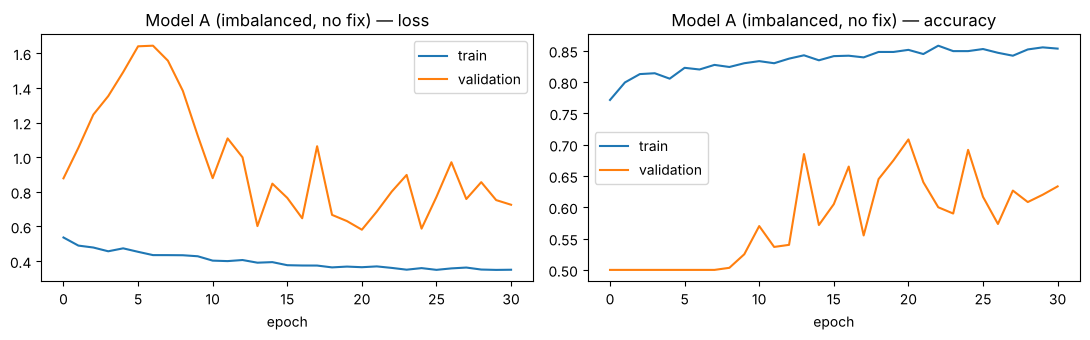

=== A: imbalanced, no fix ===
              precision    recall  f1-score   support

         cat      0.666     0.864     0.752       500
         dog      0.806     0.566     0.665       500

    accuracy                          0.715      1000
   macro avg      0.736     0.715     0.709      1000
weighted avg      0.736     0.715     0.709      1000



In [8]:
keras.utils.set_random_seed(SEED)
model_a = build_cnn()
history_a = train(model_a)
plot_history(history_a, "Model A (imbalanced, no fix)", "history_model_a.png")
result_a, cm_a = evaluate(model_a, "A: imbalanced, no fix")

## 10. Resolving the Imbalance — Class Weighting
**Strategy:** give each class a weight inversely proportional to its frequency, so that misclassifying a (rare) dog costs as much in
total as misclassifying the (common) cats:

$$w_c = \frac{N_{total}}{N_{classes} \times N_c}$$

Here that gives **cat ≈ 0.62** and **dog = 2.5**: each dog image counts 4× as much as a cat image in the loss.

*Why class weights instead of resampling?*
* **Undersampling** cats would throw away 900 real images — wasteful on an already small dataset.
* **Oversampling** dogs repeats the same 300 images, which raises the risk of memorising them.
* **Class weighting** keeps all data, changes nothing about the inputs, and is a one-line change to `model.fit`.

In [9]:
from sklearn.utils.class_weight import compute_class_weight

weights = compute_class_weight(class_weight="balanced", classes=np.array([0, 1]), y=np.array(train_labels))
class_weight = {0: weights[0], 1: weights[1]}
print("Class weights:", {CLASS_NAMES[k]: round(v, 3) for k, v in class_weight.items()})

Class weights: {'cat': np.float64(0.625), 'dog': np.float64(2.5)}


## 11. Experiment B — Same CNN retrained with class weights

Epoch 1/60


47/47 - 18s - 389ms/step - accuracy: 0.5847 - loss: 0.7085 - val_accuracy: 0.5000 - val_loss: 0.7351 - learning_rate: 0.0010


Epoch 2/60


47/47 - 17s - 355ms/step - accuracy: 0.6227 - loss: 0.7008 - val_accuracy: 0.5000 - val_loss: 0.7593 - learning_rate: 0.0010


Epoch 3/60


...

Epoch 40/60


47/47 - 21s - 439ms/step - accuracy: 0.8027 - loss: 0.4261 - val_accuracy: 0.7550 - val_loss: 0.5547 - learning_rate: 3.1250e-05


Epoch 41/60


47/47 - 17s - 363ms/step - accuracy: 0.8100 - loss: 0.4160 - val_accuracy: 0.7517 - val_loss: 0.5594 - learning_rate: 3.1250e-05


Training time: 12.8 min, epochs run: 41


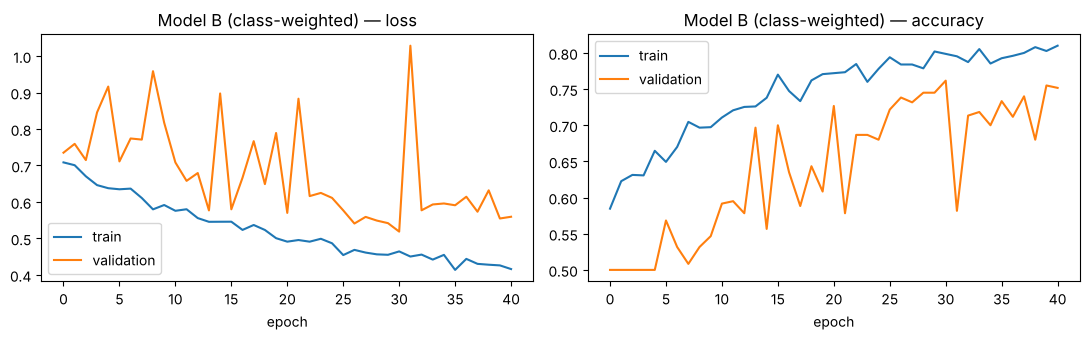

=== B: class-weighted ===
              precision    recall  f1-score   support

         cat      0.707     0.820     0.759       500
         dog      0.786     0.660     0.717       500

    accuracy                          0.740      1000
   macro avg      0.746     0.740     0.738      1000
weighted avg      0.746     0.740     0.738      1000



In [10]:
keras.utils.set_random_seed(SEED)
model_b = build_cnn()
history_b = train(model_b, class_weight=class_weight)
plot_history(history_b, "Model B (class-weighted)", "history_model_b.png")
result_b, cm_b = evaluate(model_b, "B: class-weighted")

## 12. Comparing the Two Models

,accuracy,balanced_accuracy,cat_recall,dog_recall,dog_f1,pred_dog_share
model,,,,,,
"A: imbalanced, no fix",0.715,0.715,0.864,0.566,0.665,0.351
B: class-weighted,0.740,0.740,0.820,0.660,0.717,0.420


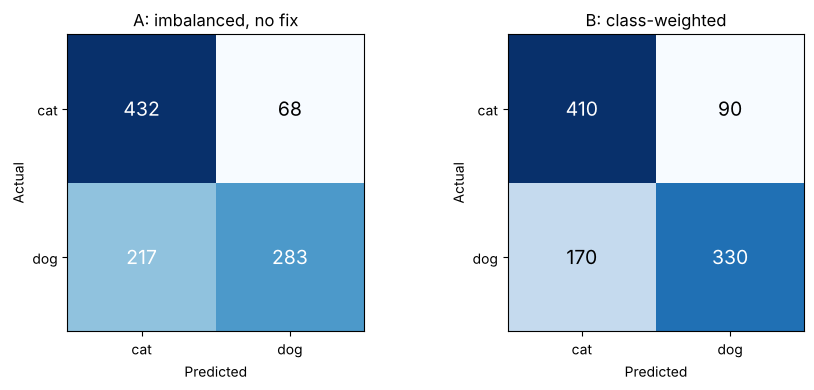

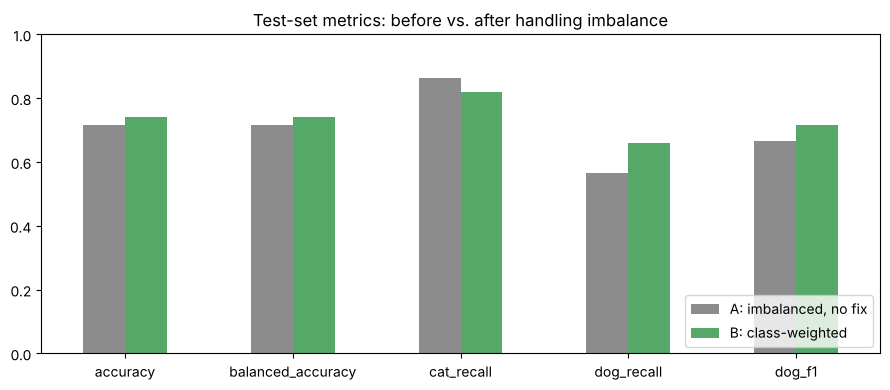

In [11]:
import pandas as pd
comparison = pd.DataFrame([result_a, result_b]).set_index("model").round(3)
display(comparison)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, cm, title in [(axes[0], cm_a, "A: imbalanced, no fix"), (axes[1], cm_b, "B: class-weighted")]:
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], CLASS_NAMES); ax.set_yticks([0, 1], CLASS_NAMES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(title)
plt.tight_layout(); plt.savefig("images/confusion_matrices.png", dpi=120); plt.show()

metrics = ["accuracy", "balanced_accuracy", "cat_recall", "dog_recall", "dog_f1"]
ax = comparison[metrics].T.plot(kind="bar", figsize=(9, 4), rot=0, color=["#8C8C8C", "#55A868"])
ax.set_ylim(0, 1); ax.set_title("Test-set metrics: before vs. after handling imbalance"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("images/metrics_comparison.png", dpi=120); plt.show()

## 13. Analysis & Conclusion

| Test-set metric (balanced, 500 cats + 500 dogs) | A: imbalanced, no fix | B: class-weighted |
|---|---|---|
| Accuracy / balanced accuracy | 71.5% | **74.0%** |
| Cat recall | **86.4%** | 82.0% |
| Dog recall | 56.6% | **66.0%** |
| Dog F1-score | 0.665 | **0.717** |
| Share of images predicted "dog" (true share: 50%) | 35.1% | 42.0% |

**What the comparison shows**
* **Model A is biased toward the majority class.** It finds 86% of cats but misses 217 of 500 dogs (43%), and it labels only 35% of images as dogs. That's the expected effect of training on 4× more cats.
* **Class weighting reduced the bias.** Dog recall rose by **9.4 points (56.6% → 66.0%)**, dog F1 from 0.665 to 0.717, and balanced accuracy by 2.5 points, with the same architecture, data and settings.
* **It's a trade-off, not free accuracy.** Cat recall fell from 86.4% to 82.0%. Class weights move the decision boundary toward the minority class, so the model makes fewer dog mistakes and slightly more cat mistakes. On a balanced test set that's a net gain.
* **The two classes are still not fully balanced** (82% vs. 66%). Class weights change how much each mistake counts, but they can't create the visual variety of the 900 dog images that were never collected.
* **The validation curves are noisy** because the validation set is small (600 images) and batch normalisation makes the early epochs unstable. Early stopping with restored best weights protects against picking a bad epoch.

**Conclusion:** A CNN built from scratch on only 1,500 training images reached **74% test accuracy**. Handling the imbalance with class weights made the model noticeably fairer to the minority class.

**Next steps:** fine-tune a pre-trained network (transfer learning, e.g. MobileNetV2), which typically reaches 95%+ on this task. Other options are combining class weights with oversampling, or tuning the decision threshold on the validation set.